In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import yaml
import time

from src.envs import create_env
from src.agents.base import pregenerate_episode, run_agent_on_episode
from src.agents.contextual import (
    BayesianSPOAgent, BayesianMSEAgent, LinUCBAgent, BayesianPFYAgent
)
from src.agents.contextual.weber_bll import WeberBLLAgent

In [2]:


# ══════════════════════════════════════════════════════════════
# Settings — loaded from experiment.yaml (matching FINAL_evaluation.ipynb)
# ══════════════════════════════════════════════════════════════

with open('../experiments/configs/experiment.yaml') as f:
    config = yaml.safe_load(f)

defaults = config['agent_defaults']
lr = defaults['lr']
lambda_reg = defaults['lambda_reg']
beta = defaults['beta']

DATASETS = {
    'portfolio_32': dict(hidden_dim=defaults['hidden_dim_small']),
    'shortest_path_8x8': dict(hidden_dim=defaults['hidden_dim_small']),
}

N_ROUNDS = 2000
N_SEEDS = 3
SEEDS = list(range(N_SEEDS))

# ══════════════════════════════════════════════════════════════
# Run — pre-generated episodes for fair comparison
# ══════════════════════════════════════════════════════════════

all_trajectories = {}

for ds_name, ds_cfg in DATASETS.items():
    dataset_config = config['datasets'][ds_name].copy()
    dataset_config.pop('env_type', None)
    dataset_config.pop('n_rounds', None)

    hidden_dim = ds_cfg['hidden_dim']

    # Detect minimize from env
    test_env = create_env(ds_name, seed=0, **dataset_config)
    minimize = getattr(test_env, 'minimize', False)
    bayes_beta = -beta if minimize else beta

    print(f'\n{"="*60}')
    print(f'{ds_name.upper()}')
    print(f'  config: {dataset_config}')
    print(f'  hp:  lr={lr}, hidden_dim={hidden_dim}, '
          f'lambda_reg={lambda_reg}, beta={beta}')
    print(f'  n_rounds={N_ROUNDS}, seeds={N_SEEDS}, minimize={minimize}')
    print(f'{"="*60}')

    for seed in SEEDS:
        # Pre-generate episode: all agents see identical data
        env = create_env(ds_name, seed=seed, **dataset_config)
        episode = pregenerate_episode(env, N_ROUNDS)

        # Create agents from a fresh env instance
        env_a = create_env(ds_name, seed=seed, **dataset_config)
        solver = env_a.solve

        common = dict(
            context_dim=env_a.context_dim, n_arms=env_a.n_arms,
            weights=env_a.weights, capacity=env_a.capacity,
        )

        agents = {
            'BayesianSPO': BayesianSPOAgent(
                **common, hidden_dim=hidden_dim, beta=bayes_beta,
                decay_rounds=N_ROUNDS, lambda_reg=lambda_reg,
                minimize=minimize, solver=solver, seed=seed,
                mask_grad=True,
            ),
            'BayesianPFY':BayesianPFYAgent(
                **common, hidden_dim=hidden_dim, beta=bayes_beta,
                decay_rounds=N_ROUNDS, lambda_reg=lambda_reg,
                minimize=minimize, solver=solver, seed=seed,
                pfy_n_samples = 2, pfy_noise ='normal', pfy_sigma = 1.,
                mask_grad=True,
            ),
        }

        print(f'\n  seed={seed}:', end='')
        for agent_name, agent in agents.items():
            t0 = time.perf_counter()
            result = run_agent_on_episode(
                agent, episode, N_ROUNDS,
                lr=lr, full_feedback=False,
            )
            dt = time.perf_counter() - t0

            all_trajectories[(agent_name, ds_name, seed)] = {
                'cumulative_regret': result['cumulative_regret'],
                'regrets': result['regrets'],
            }
            print(f'  {agent_name}={result["final_regret"]:.0f}({dt:.1f}s)', end='')
        print()

print('\nDone!')




PORTFOLIO_32
  config: {'num_assets': 32, 'context_dim': 5, 'noise_width': 0.25}
  hp:  lr=0.001, hidden_dim=16, lambda_reg=1.0, beta=1.0
  n_rounds=2000, seeds=3, minimize=False

  seed=0:  BayesianSPO=37(22.5s)  BayesianPFY=37(26.4s)

  seed=1:  BayesianSPO=39(21.6s)  BayesianPFY=39(27.1s)

  seed=2:  BayesianSPO=36(21.8s)  BayesianPFY=36(26.4s)

SHORTEST_PATH_8X8
  config: {'grid_size': 8, 'context_dim': 5, 'noise_width': 0.25}
  hp:  lr=0.001, hidden_dim=16, lambda_reg=1.0, beta=1.0
  n_rounds=2000, seeds=3, minimize=True

  seed=0:  BayesianSPO=3169(8.4s)  BayesianPFY=3751(8.4s)

  seed=1:  BayesianSPO=3104(8.1s)  BayesianPFY=3761(8.7s)

  seed=2:  BayesianSPO=3285(8.2s)  BayesianPFY=4052(8.5s)

Done!


In [3]:


import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({'font.size': 12})

AGENT_NAMES = ['BayesianPFY', 'BayesianSPO']
COLORS = {
    'BayesianPFY': '#1f77b4',
    'BayesianSPO': '#d62728',
}
LABELS = {
    'BayesianPFY': 'BayesianPFY',
    'BayesianSPO': 'BayesianSPO',
}
DS_NAMES = list(DATASETS.keys())

def get_trajectories(ds_name, agent_name, metric='cumulative_regret'):
    """Collect trajectories across seeds for one agent on one dataset."""
    trajs = []
    for s in SEEDS:
        key = (agent_name, ds_name, s)
        if key in all_trajectories:
            trajs.append(all_trajectories[key][metric])
    return np.array(trajs) if trajs else np.array([])



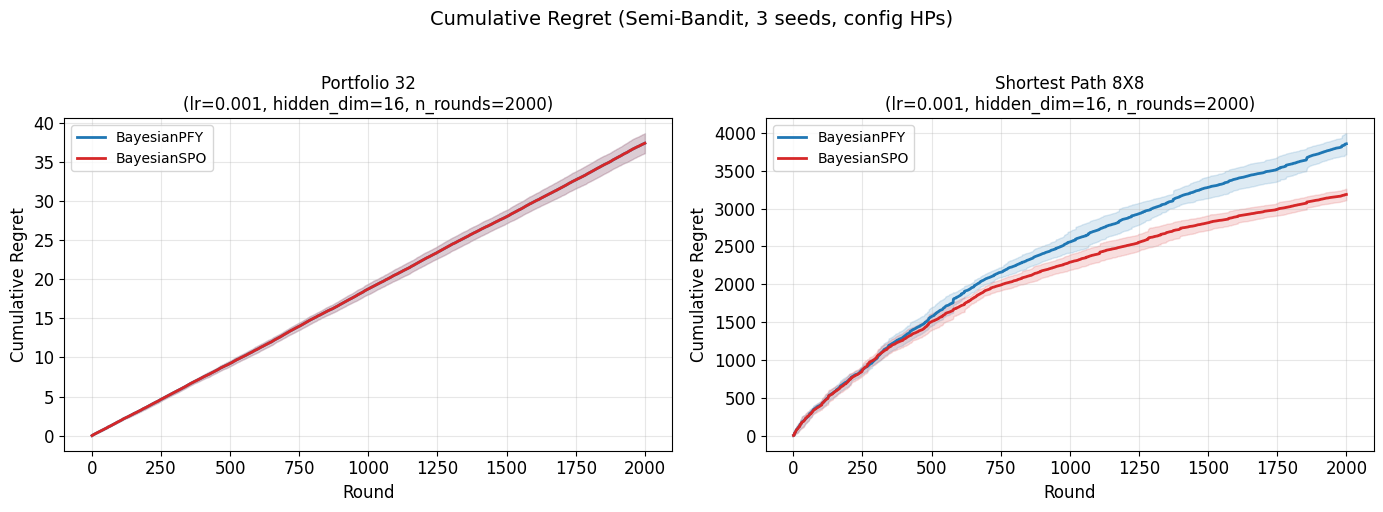

In [4]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ds_name in zip(axes, DS_NAMES):
    rounds = np.arange(1, N_ROUNDS + 1)
    
    for agent_name in AGENT_NAMES:
        trajs = get_trajectories(ds_name, agent_name)
        if len(trajs) == 0:
            continue
        mean = trajs.mean(axis=0)
        std = trajs.std(axis=0)
        
        ax.plot(rounds, mean, color=COLORS[agent_name], 
                label=LABELS[agent_name], linewidth=2)
        ax.fill_between(rounds, mean - std, mean + std,
                        color=COLORS[agent_name], alpha=0.15)
    
    title = ds_name.replace('_', ' ').title()
    ax.set_title(f'{title}\n(lr={lr}, hidden_dim={DATASETS[ds_name]["hidden_dim"]}, '
                 f'n_rounds={N_ROUNDS})', fontsize=12)
    ax.set_xlabel('Round')
    ax.set_ylabel('Cumulative Regret')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

fig.suptitle(f'Cumulative Regret (Semi-Bandit, {N_SEEDS} seeds, config HPs)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

